# Sleep Health and Lifestyle: Analysis Report

**Student Name:** Mubashra Munir 


**Student ID:** 20178096 


**Course:** BSBINS401 - Introduction to Data Visualisation Tools - ICT40120 (Data Science and AI)

## Table of Contents

1. [Introduction](#introduction)
2. [Research Objectives and Strategy](#research-objectives-and-strategy)
   - 2.1 [Research Objectives](#research-objectives)
   - 2.2 [Research Strategy](#research-strategy)
3. [Data Collection and Organization](#data-collection-and-organization)
   - 3.1 [Data Access and Extraction](#data-access-and-extraction)
   - 3.2 [Data Organization](#data-organization)
   - 3.3 [Data Security Measures](#data-security-measures)
4. [Data Analysis and Findings](#data-analysis-and-findings)
   - 4.1 [Analysis Methods](#analysis-methods)
   - 4.2 [Findings and Visualizations](#findings-and-visualizations)
5. [Conclusions](#conclusions)
6. [References](#references)
7. [Appendices](#appendices)


## Introduction

Poor sleep affects concentration, health and productivity, and it is closely tied to everyday habits such as stress, activity and body weight. This report analyses the *Sleep Health and Lifestyle Dataset* (Tharmalingam, 2023), which records sleep, lifestyle and health measures for 374 working adults across 11 occupations.

The purpose of the analysis is to help an organisation, such as a workplace wellbeing team, understand which lifestyle and health factors are most closely linked to sleep quality and sleep disorders, so that support programs can be targeted where they will have the most effect.

## Research Objectives and Strategy

### 2.1 Research Objectives

- **Objective 1:** Determine how stress level and lifestyle factors (sleep duration, physical activity, daily steps) relate to quality of sleep.
- **Objective 2:** Identify which health factors, particularly BMI category, are linked to sleep disorders (Insomnia and Sleep Apnea).
- **Objective 3:** Compare sleep quality across occupations to see which groups of workers are most at risk.

These objectives align with the organisation's need for practical, evidence-based insights. Knowing *which* factors matter and *who* is most affected allows wellbeing resources to be directed at the right people and the right issues.

### 2.2 Research Strategy

A quantitative, descriptive approach was used because the dataset is structured and numeric. The strategy had four stages:

1. **Load and inspect** the data in Python to understand its structure and quality.
2. **Clean and organise** it (fix labels, split fields, handle missing values, check duplicates and outliers).
3. **Analyse** relationships using summary statistics, group comparisons and correlation, supported by visualisations.
4. **Interpret** each result against the objectives and draw conclusions.

Python with Pandas, Matplotlib and Seaborn was chosen because it is the tool set specified for the assessment, it handles tabular data efficiently, and every step is recorded in code, which makes the analysis repeatable and easy to check.

---

## Data Collection and Organization

### 3.1 Data Access and Extraction

- **Data Access:** The dataset was downloaded as a CSV file (*Sleep Health and Lifestyle Dataset.csv*) from the Kaggle.
- **Data Extraction:** The file was read into a Pandas DataFrame. It contains 374 rows and 13 columns: Person ID, Gender, Age, Occupation, Sleep Duration, Quality of Sleep, Physical Activity Level, Stress Level, BMI Category, Blood Pressure, Heart Rate, Daily Steps and Sleep Disorder. All columns were relevant to at least one objective, so all were kept.

The code below loads and cleans the data; it is used by every chart in Section 4.

In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

data = pd.read_csv("Sleep Health and Lifestyle Dataset.csv")
display(data.head())
print("Missing values per column:")
data.info()
print("Rows, columns:", data.shape)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


Missing values per column:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1

None

Rows, columns: (374, 13)


### 3.2 Data Organization

- **Data Cleaning:**
  - **Missing Sleep Disorder values:** 219 of 374 rows had no disorder recorded. These represent people *without* a disorder, not unknown values, so they were filled with "None".
  - **Inconsistent BMI labels:** "Normal" and "Normal Weight" described the same group and were merged into "Normal".
  - **Combined Blood Pressure field:** stored as text such as "126/83"; it was split into numeric **Systolic** and **Diastolic** columns.
  - **Duplicates:** no exact duplicate rows were found. Many rows share the same values apart from Person ID, but each ID is a different person, so all rows were kept.
  - **Outliers:** box plots showed outliers only in Heart Rate (15 values between 80 and 86 bpm). These are realistic resting heart rates, so they were kept as genuine data (see Appendix B).
- **Data Formatting:** Numeric columns were confirmed as integer or float types, and a **Stress Group** column (High = stress 7 or above, Low = below 7) was added to support comparisons. 

In [8]:
# Fix labels and missing values
data["BMI Category"] = data["BMI Category"].replace({"Normal Weight": "Normal"})
data["Sleep Disorder"] = data["Sleep Disorder"].fillna("None")

# Split blood pressure into two numeric columns
data[["Systolic", "Diastolic"]] = data["Blood Pressure"].str.split("/", expand=True).astype(int)
data = data.drop(columns=["Blood Pressure"])

# Helper columns
data["Stress Group"] = np.where(data["Stress Level"] >= 7, "High", "Low")
data["Has Disorder"] = data["Sleep Disorder"] != "None"

# Duplicate check
print("Exact duplicate rows:", data.duplicated().sum())
print("Rows identical apart from Person ID:", data.drop(columns="Person ID").duplicated().sum())

# Save the cleaned copy separately from the original
data.to_csv("Cleaned Sleep Data.csv", index=False)
print("Cleaned data:", data.shape)

Exact duplicate rows: 0
Rows identical apart from Person ID: 242
Cleaned data: (374, 16)


### 3.3 Data Security Measures

- **Security Protocols:**
  - The dataset is **anonymised**: people are identified only by a Person ID, with no names or contact details.
  - Files were stored in a **private, password-protected** folder on a personal device and backed up to the student's own cloud account only.
  - The **original file was never modified**; all cleaning was done on a copy in code and saved as a new file, so the source data stays intact.
  - Data was not shared outside the course LMS.
- **Compliance:** These steps follow the organisation's data-handling policy and the principles of the *Australian Privacy Principles* (OAIC, 2023): collect only what is needed, keep it secure, and use it only for its stated purpose.

---

## Data Analysis and Findings

### 4.1 Analysis Methods

- **Software and Libraries:** Python 3 in Jupyter Notebook, using Pandas (data handling), NumPy (calculations), Matplotlib and Seaborn (visualisation).
- **Techniques:**
  - Descriptive statistics (mean, median, counts) for each variable.
  - Group comparisons, for example sleep quality by occupation and disorder rate by BMI category.
  - Pearson correlation to measure how strongly each numeric factor relates to sleep quality.
  - Visualisations: scatter plots, bar charts, box plots and a correlation heatmap.

### 4.2 Findings and Visualizations

In [9]:
# Correlation of each numeric factor with Quality of Sleep
numeric_cols = ["Sleep Duration", "Stress Level", "Heart Rate", "Age",
                "Physical Activity Level", "Daily Steps", "Systolic", "Diastolic"]
corr = data[numeric_cols + ["Quality of Sleep"]].corr()["Quality of Sleep"].drop("Quality of Sleep")
print(corr.sort_values().round(2))

Stress Level              -0.90
Heart Rate                -0.66
Systolic                  -0.12
Diastolic                 -0.11
Daily Steps                0.02
Physical Activity Level    0.19
Age                        0.47
Sleep Duration             0.88
Name: Quality of Sleep, dtype: float64


#### Finding 1: Higher stress is strongly linked to poorer sleep

- **Description:** Stress Level has the strongest relationship with sleep quality of any factor (r = −0.90). Average sleep quality falls from about 9.0 at stress level 3 to about 5.9 at stress level 8. Stress is also linked to sleep disorders: **70%** of high-stress people (level 7 or above) have Insomnia or Sleep Apnea, compared with **28%** of low-stress people.
- **Evidence:** Figure 1 and Figure 2.

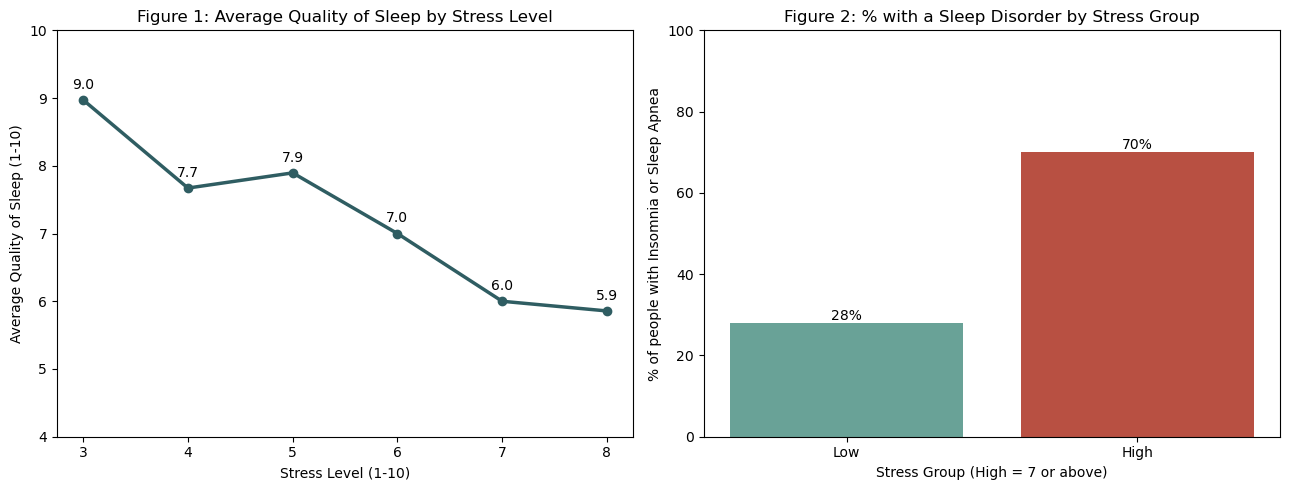

Stress Group
Low     28.0
High    70.0
Name: Has Disorder, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Figure 1: average sleep quality at each stress level
avg_q = data.groupby("Stress Level")["Quality of Sleep"].mean()
axes[0].plot(avg_q.index, avg_q.values, marker="o", color="#2F5D62", linewidth=2.5)
for x, y in avg_q.items():
    axes[0].annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
axes[0].set_title("Figure 1: Average Quality of Sleep by Stress Level")
axes[0].set_xlabel("Stress Level (1-10)")
axes[0].set_ylabel("Average Quality of Sleep (1-10)")
axes[0].set_ylim(4, 10)

# Figure 2: share of people with a sleep disorder, high vs low stress
rate = data.groupby("Stress Group")["Has Disorder"].mean().reindex(["Low", "High"]) * 100
bars = axes[1].bar(rate.index, rate.values, color=["#69A297", "#B85042"])
axes[1].bar_label(bars, fmt="%.0f%%")
axes[1].set_title("Figure 2: % with a Sleep Disorder by Stress Group")
axes[1].set_xlabel("Stress Group (High = 7 or above)")
axes[1].set_ylabel("% of people with Insomnia or Sleep Apnea")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

print(rate.round(1))

- **Interpretation:** Stress is the clearest single warning sign of poor sleep in this dataset. Sleep Duration is almost as closely linked (r = +0.88), which suggests stressed people also sleep fewer hours. By contrast, Daily Steps (r = 0.02) and Physical Activity (r = 0.19) show only weak links to sleep quality.

#### Finding 2: BMI category is the strongest link to sleep disorders

- **Description:** Only **7%** of people with a Normal BMI have a sleep disorder. This rises to **87%** for Overweight people and **100%** for Obese people. Overweight people are split almost evenly between Insomnia and Sleep Apnea.
- **Evidence:** Figure 3.

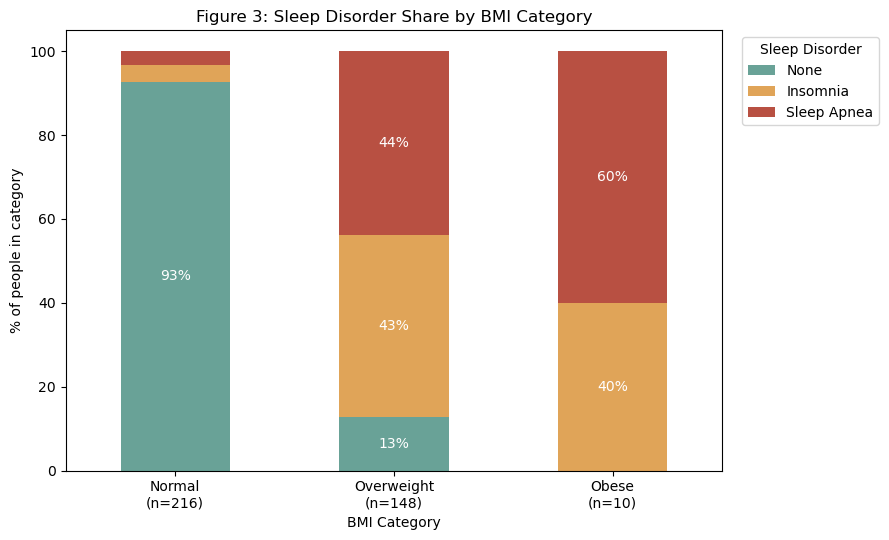

Sleep Disorder  None  Insomnia  Sleep Apnea
BMI Category                               
Normal          92.6       4.2          3.2
Overweight      12.8      43.2         43.9
Obese            0.0      40.0         60.0


In [11]:
order = ["Normal", "Overweight", "Obese"]
share = pd.crosstab(data["BMI Category"], data["Sleep Disorder"], normalize="index").reindex(order) * 100
share = share[["None", "Insomnia", "Sleep Apnea"]]
counts = data["BMI Category"].value_counts().reindex(order)

ax = share.plot(kind="bar", stacked=True, figsize=(9, 5.5),
                color=["#69A297", "#E0A458", "#B85042"], rot=0)
ax.set_title("Figure 3: Sleep Disorder Share by BMI Category")
ax.set_xlabel("BMI Category")
ax.set_ylabel("% of people in category")
ax.set_xticklabels([f"{c}\n(n={counts[c]})" for c in order])
for container in ax.containers:
    ax.bar_label(container, fmt=lambda v: f"{v:.0f}%" if v >= 5 else "", label_type="center", color="white")
ax.legend(title="Sleep Disorder", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(share.round(1))

- **Interpretation:** Body weight is very closely associated with sleep disorders, which is consistent with Sleep Apnea's known link to excess weight. The Obese group is small (10 people), so the 100% figure should be treated with caution, but the gap between Normal and Overweight (148 people) is large and reliable.

#### Finding 3: Sleep quality differs by occupation, in line with stress

- **Description:** Engineers have the highest median sleep quality (9) and the lowest average stress (3.9). Lawyers and Accountants follow with a median of 8. Salespeople and Nurses have the lowest median among the larger groups (6). Nurses show a very wide spread, from 5 to 9. Scientists, Sales Representatives, Software Engineers and the Manager have fewer than 5 people each, so their results are not reliable.
- **Evidence:** Figure 4.

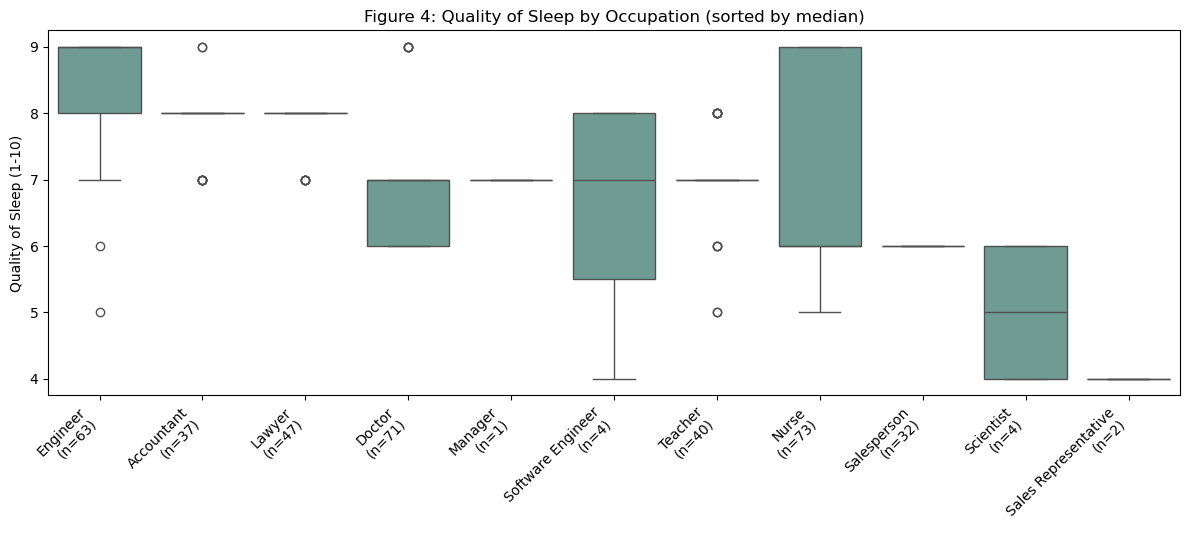

                      People  Median_Sleep_Quality  Avg_Stress
Occupation                                                    
Engineer                  63                   9.0        3.89
Accountant                37                   8.0        4.59
Lawyer                    47                   8.0        5.06
Doctor                    71                   7.0        6.73
Manager                    1                   7.0        5.00
Software Engineer          4                   7.0        6.00
Teacher                   40                   7.0        4.53
Nurse                     73                   6.0        5.55
Salesperson               32                   6.0        7.00
Scientist                  4                   5.0        7.00
Sales Representative       2                   4.0        8.00


In [13]:
occ_order = data.groupby("Occupation")["Quality of Sleep"].median().sort_values(ascending=False).index
occ_n = data["Occupation"].value_counts()

plt.figure(figsize=(12, 5.5))
sns.boxplot(data=data, x="Occupation", y="Quality of Sleep", order=occ_order, color="#69A297")
plt.xticks(range(len(occ_order)), [f"{o}\n(n={occ_n[o]})" for o in occ_order], rotation=45, ha="right")
plt.title("Figure 4: Quality of Sleep by Occupation (sorted by median)")
plt.xlabel("")
plt.ylabel("Quality of Sleep (1-10)")
plt.tight_layout()
plt.show()

summary = data.groupby("Occupation").agg(People=("Person ID", "count"),
                                         Median_Sleep_Quality=("Quality of Sleep", "median"),
                                         Avg_Stress=("Stress Level", "mean"))
print(summary.sort_values("Median_Sleep_Quality", ascending=False).round(2))

- **Interpretation:** Occupations with lower stress tend to have better sleep. This suggests that occupation acts mainly as a stand-in for workload and stress rather than being a direct cause of poor sleep.

---

## Conclusions

- **Conclusion 1 (Objectives 1 and 3):** Stress is the factor most closely linked to poor sleep. It has a very strong negative relationship with sleep quality (r = −0.90), and high-stress people are 2.5 times as likely to have a sleep disorder (70% vs 28%). Differences between occupations mostly follow the same stress pattern.
- **Conclusion 2 (Objective 2):** BMI is the strongest link to sleep disorders. 87% of Overweight people and all Obese people have Insomnia or Sleep Apnea, compared with 7% of people with a Normal BMI.

**Implications and recommendations for the organisation:**

1. **Stress management:** introduce stress-reduction support (workload reviews, flexible scheduling, wellbeing sessions), focusing first on the highest-stress roles, such as Sales staff and Doctors.
2. **Healthy weight support:** offer health checks and weight-management programs, and encourage staff who are overweight or snore heavily to be screened for Sleep Apnea.
3. **Monitor sleep:** include sleep quality and stress questions in staff wellbeing surveys to track progress over time.

**Limitations:** The results show associations, not cause and effect. The dataset is small, some occupation groups have very few people, and the Kaggle description notes the data is synthetic and intended for illustration, so findings should be confirmed with real staff data before major decisions are made.

---

## References

- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55
- Office of the Australian Information Commissioner. (2023). *Australian Privacy Principles*. OAIC. https://www.oaic.gov.au/privacy/australian-privacy-principles
- The pandas development team. (2024). *pandas* (Version 2) [Computer software]. https://pandas.pydata.org
- Tharmalingam, L. (2023). *Sleep Health and Lifestyle Dataset*. Kaggle. https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021

---

## Appendices

### Appendix A: Code Snippets

The loading, cleaning and chart code is included in the cells above (Sections 3 and 4). The additional checks below were used during data exploration.

In [16]:
# Check categorical values before cleaning
print("BMI Category (original):", list(data["BMI Category"].unique()))
print("Sleep Disorder (original):", data["Sleep Disorder"].value_counts(dropna=False).to_dict())

# Heart Rate outlier check using the IQR method
Q1, Q3 = data["Heart Rate"].quantile([0.25, 0.75])
IQR = Q3 - Q1
outliers = data[(data["Heart Rate"] < Q1 - 1.5 * IQR) | (data["Heart Rate"] > Q3 + 1.5 * IQR)]
print(f"Heart Rate outliers: {len(outliers)} (values: {sorted(int(v) for v in outliers['Heart Rate'].unique())})")

NameError: name 'raw' is not defined